In [33]:
import pandas as pd
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
%matplotlib inline
import seaborn as sns
import missingno as msno
from scipy import stats
!pip install fuzzywuzzy
import fuzzywuzzy
from fuzzywuzzy import process
!pip install scikit-learn
from sklearn import preprocessing


[notice] A new release of pip is available: 25.2 -> 25.3
[notice] To update, run: python.exe -m pip install --upgrade pip

[notice] A new release of pip is available: 25.2 -> 25.3
[notice] To update, run: python.exe -m pip install --upgrade pip


  Using cached scikit_learn-1.7.2-cp313-cp313-win_amd64.whl.metadata (11 kB)
  Using cached joblib-1.5.2-py3-none-any.whl.metadata (5.6 kB)
Using cached scikit_learn-1.7.2-cp313-cp313-win_amd64.whl (8.7 MB)
Using cached joblib-1.5.2-py3-none-any.whl (308 kB)

   ---------------------------------------- 0/2 [joblib]
   ---------------------------------------- 0/2 [joblib]
   ---------------------------------------- 0/2 [joblib]
   ---------------------------------------- 0/2 [joblib]
   ---------------------------------------- 0/2 [joblib]
   ---------------------------------------- 0/2 [joblib]
   ---------------------------------------- 0/2 [joblib]
   ---------------------------------------- 0/2 [joblib]
   ---------------------------------------- 0/2 [joblib]
   ---------------------------------------- 0/2 [joblib]
   ---------------------------------------- 0/2 [joblib]
   ---------------------------------------- 0/2 [joblib]
   ---------------------------------------- 0/2 [joblib]

In [3]:
df = pd.read_csv('datasets/diabetes_prediction_dataset_uncleaned.csv')

In [4]:
missing_values_count = df.isnull().sum()
missing_values_count

gender                 2
age                    3
hypertension           0
heart_disease          0
smoking_history        0
bmi                    0
HbA1c_level            3
blood_glucose_level    0
diabetes               0
dtype: int64

In [5]:
df.shape

(100010, 9)

In [6]:
df.dropna(subset=['gender'], inplace=True)

In [7]:
missing_values_count = df.isnull().sum()
missing_values_count

gender                 0
age                    3
hypertension           0
heart_disease          0
smoking_history        0
bmi                    0
HbA1c_level            3
blood_glucose_level    0
diabetes               0
dtype: int64

In [8]:
df.shape

(100008, 9)

In [9]:
df = df.fillna({
    'age': df['age'].median(),
    'HbA1c_level': df['age'].mean(),
})

In [10]:
missing_values_count = df.isnull().sum()
missing_values_count

gender                 0
age                    0
hypertension           0
heart_disease          0
smoking_history        0
bmi                    0
HbA1c_level            0
blood_glucose_level    0
diabetes               0
dtype: int64

In [11]:
smoking = df['smoking_history'].unique()
smoking.sort()
smoking

array(['No Info', 'NoInfo', 'Not Info', 'curent', 'current', 'ever',
       'former', 'never', 'noever', 'not current'], dtype=object)

In [14]:
matches = fuzzywuzzy.process.extract(
       "No Info",
       smoking,
       limit=10,
       scorer=fuzzywuzzy.fuzz.token_sort_ratio)
matches

[('No Info', 100),
 ('Not Info', 93),
 ('NoInfo', 62),
 ('not current', 44),
 ('former', 31),
 ('noever', 31),
 ('never', 17),
 ('curent', 15),
 ('current', 14),
 ('ever', 0)]

In [16]:
def replace_inconsistent_data(df, column, string_to_match, min_ratio=47):
# dapatkan unique string
    strings = df[column].unique() 
# 10 teratas uniquer string
    matches = fuzzywuzzy.process.extract(
       string_to_match,
       strings,
       limit=10,
       scorer=fuzzywuzzy.fuzz.token_sort_ratio)
# dapatkan kata dengan rasio kemiripan > 90
    close_matches = [
        matches[0] for matches in matches if matches[1] >= min_ratio
    ]
# dapatkan rows yang mirip pada kolom tertentu
    rows_with_matches = df[column].isin(close_matches)
# replace dengan string_to_match
    df.loc[rows_with_matches, column] = string_to_match
    print("Penggantian data selesai!")

In [19]:
replace_inconsistent_data(df=df,
column='smoking_history',
string_to_match="No Info")

Penggantian data selesai!


In [20]:
smoking = df['smoking_history'].unique()
# urutkan secara alphabet
smoking.sort()
smoking

array(['No Info', 'curent', 'current', 'ever', 'former', 'never',
       'noever', 'not current'], dtype=object)

<Axes: >

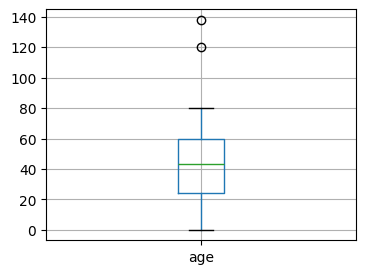

In [21]:
plt.figure(figsize=(4,3))
df.boxplot(column='age')

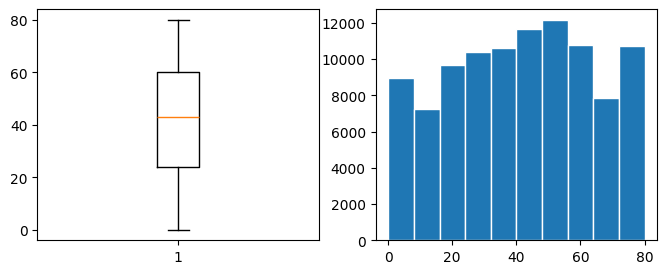

In [22]:
df.loc[df['age'] > 100, 'age'] = df['age'].mean()

plt.figure(figsize=(8,3))
plt.subplot(1, 2, 1)
plt.boxplot(df['age'])
plt.subplot(1, 2, 2)
plt.hist(df['age'], edgecolor='white')
plt.show()

In [23]:
duplicate = df[df.duplicated()]
duplicate

,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes
2756,Male,80.0,0,0,No Info,27.32,6.6,159,0
3272,Female,80.0,0,0,No Info,27.32,3.5,80,0
3418,Female,19.0,0,0,No Info,27.32,6.5,100,0
3939,Female,78.0,1,0,former,27.32,3.5,130,0
3960,Male,47.0,0,0,No Info,27.32,6.0,200,0
...,...,...,...,...,...,...,...,...,...
100001,Female,55.0,0,0,never,35.42,6.5,140,0
100002,Female,55.0,0,0,never,35.42,6.5,140,0
100003,Female,55.0,0,0,never,35.42,6.5,140,0
100005,Female,13.0,0,0,No Info,31.31,5.0,126,0


In [24]:
df.drop_duplicates(inplace=True)
duplicate = df[df.duplicated()]
duplicate

,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes


In [25]:
gender = df['gender'].unique()
gender

array(['Female', 'Male', 'Other'], dtype=object)

In [34]:
from sklearn import preprocessing
label_encoder = preprocessing.LabelEncoder()
df['gender'] = label_encoder.fit_transform(df['gender'])
df.head()

,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes
0,0,80.0,0,1,never,25.19,6.6,140,0
1,0,54.0,0,0,No Info,27.32,6.6,80,0
2,1,28.0,0,0,never,27.32,5.7,158,0
3,0,36.0,0,0,current,23.45,5.0,155,0
4,1,76.0,1,1,current,20.14,4.8,155,0


In [35]:
from sklearn.model_selection import train_test_split

# ukuran untuk data test adalah 20% (0,2) dari total data
train, test = train_test_split(df, test_size=0.2)

In [36]:
train.shape

(76919, 9)

In [37]:
test.shape

(19230, 9)